In [1]:
import numpy as np
import h2py
import pickle
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy
import pandas
import demes


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [2]:
# Load MLE models
mle_models = {}
buffers = ["intergenic", "1e-4M_ccds_flank", "1e-3M_ccds_flank"]
for rmap in ["bherer", "zhou-JHS"]:
    for buffer in buffers:
        fnames = []
        lls = []
        for trial in range(30):
            fname = f"fitted_models/main_fit_{buffer}_{rmap}_try_{trial}.yaml"
            fnames.append(fname)
            g = demes.load(fname)
            lls.append(g.metadata["opt_info"]["ll"])
        fname = fnames[np.argmax(lls)]
        pvals, pnames = h2py.inference.load_params(fname, "full_model_params.yaml")
        mle_models[(rmap, buffer)] = (pvals, pnames)
        print(fname, np.max(lls))

fitted_models/main_fit_intergenic_bherer_try_12.yaml -900.697475698907
fitted_models/main_fit_1e-4M_ccds_flank_bherer_try_19.yaml -579.3087104019238
fitted_models/main_fit_1e-3M_ccds_flank_bherer_try_29.yaml -469.87488432240605
fitted_models/main_fit_intergenic_zhou-JHS_try_13.yaml -950.4854028524479
fitted_models/main_fit_1e-4M_ccds_flank_zhou-JHS_try_10.yaml -582.2087163551628
fitted_models/main_fit_1e-3M_ccds_flank_zhou-JHS_try_11.yaml -467.08293630859254


In [3]:
for rmap in ["bherer", "zhou-JHS"]:
    for buffer in buffers:
        data = []
        for rep in range(500):
            fname = f"fitted_models/boot_fit_{buffer}_{rmap}_rep_{rep}.yaml"
            pvals, pnames = h2py.inference.load_params(fname, "full_model_params.yaml")
            data.append(pvals)
        mle = mle_models[(rmap, buffer)][0]
        lower_CI = np.quantile(data, 0.025, axis=0) 
        upper_CI = np.quantile(data, 0.975, axis=0) 
        df = pandas.DataFrame({"name": pnames, "MLE": mle, "CI_lower": lower_CI, "CI_upper": upper_CI})
        df.to_csv(f"bootstrap_{rmap}_{buffer}.csv")

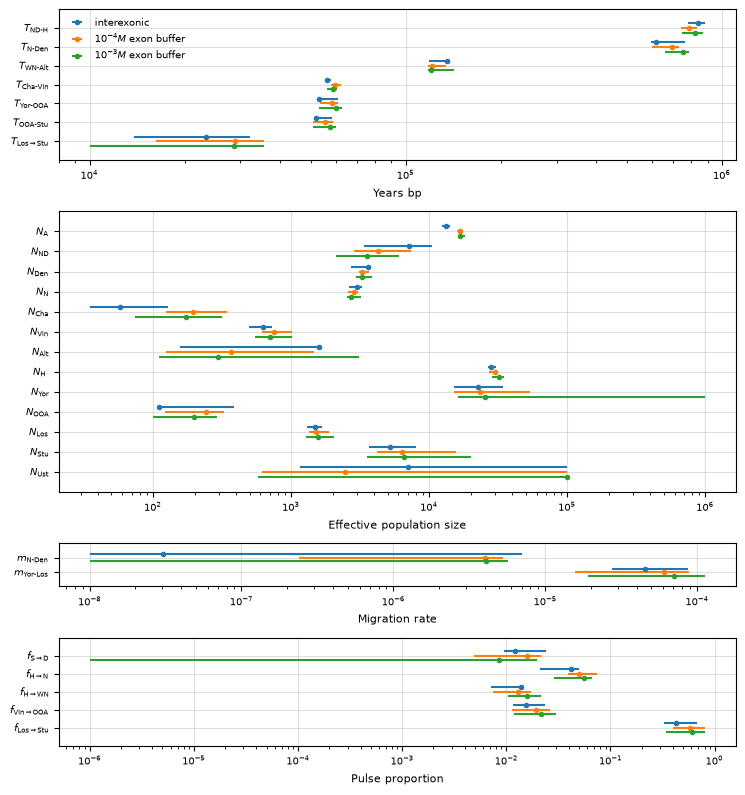

In [5]:
df0 = pandas.read_csv("bootstrap_bherer_intergenic.csv")
df1 = pandas.read_csv("bootstrap_bherer_1e-4M_ccds_flank.csv")
df2 = pandas.read_csv("bootstrap_bherer_1e-3M_ccds_flank.csv")
groups = [
    {"params": ['T_NDH', 'T_ND', 'T_AWN', 'T_CV', 'T_OOA', 'T_SL', 'T_L_S'], "log": True},
    {"params": ['N_Anc', 'N_ND', 'N_Den', 'N_N', 'N_Chag', 'N_Vin', 'N_Alt', 'N_MH', 'N_Yor', 'N_OOA', 'N_Los', 'N_Stut', 'N_Ust'],
     "log": True},
    {"params": ["m_ND", "m_LY"], "log": True},
    {"params": ["p_S_D", "p_H_N", "p_H_WN", "p_N_OOA", "p_L_S"], "log": True}
]

x_labels = ["Years bp", "Effective population size", "Migration rate",  "Pulse proportion"]
param_labels = {
    'T_NDH': r'$T_{\text{ND-H}}$',
    'T_ND': r'$T_{\text{N-Den}}$', 
    'T_AWN': r'$T_{\text{WN-Alt}}$', 
    'T_CV': r'$T_{\text{Cha-Vin}}$', 
    'T_OOA': r'$T_{\text{Yor-OOA}}$', 
    'T_SL': r'$T_{\text{OOA-Stu}}$', 
    'T_L_S': r'$T_{\text{Los}\to\text{Stu}}$', 
    'N_Anc': r'$N_{\text{A}}$',
    "N_S": r"$N_{\text{S}}$ (fixed)",
    'N_ND': r'$N_{\text{ND}}$', 
    'N_N': r'$N_{\text{N}}$', 
    'N_MH': r'$N_{\text{H}}$ ', 
    'N_OOA': r'$N_{\text{OOA}}$',
    'N_Alt': r'$N_{\text{Alt}}$', 
    'N_Chag': r'$N_{\text{Cha}}$', 
    'N_Vin': r'$N_{\text{Vin}}$', 
    'N_Den': r'$N_{\text{Den}}$',
    'N_Los': r'$N_{\text{Los}}$',
    'N_Ust': r'$N_{\text{Ust}}$',
    'N_Stut': r'$N_{\text{Stu}}$',
    'N_Yor': r'$N_{\text{Yor}}$', 
    'm_ND': r'$m_{\text{N-Den}}$', 
    'm_LY': r'$m_{\text{Yor-Los}}$', 
    'p_S_D': r'$f_{\text{S} \to \text{D}}$', 
    'p_H_N': r'$f_{\text{H} \to \text{N}}$',
    'p_H_WN': r'$f_{\text{H} \to \text{WN}}$', 
    'p_N_OOA': r'$f_{\text{Vin}\to\text{OOA}}$', 
    'p_L_S': r'$f_{\text{Los}\to\text{Stu}}$',
}

h2py.plotting.plot_param_distributions(
    [df0, df1, df2],
    groups=groups,
    param_labels=param_labels,
    data_labels=["interexonic", "$10^{-4}M$ exon buffer", "$10^{-3}M$ exon buffer"],
    figsize=(7.5, 8),
    x_labels=x_labels,
    spread=0.25,
    out="../../figures/buffer_param_distrs.pdf"
)